# 02b · Backbone prototype

Does extracting a backbone of the forwarding graph *before* community detection change the communities,
and with them the boundary used by RQ1? Settings were fixed before running (`docs/DECISIONS.md` **D14**).
**The partition from notebook 02 stays the main boundary until this comparison has been discussed.**

**What a backbone is.** Many edges carry one or two forwards and may be noise. A backbone keeps only the
edges whose weight is significantly higher than expected given how active their two endpoints are:
- **Noise-corrected backbone (NC)** (Coscia & Neffke 2017). The expected weight of `i → j` is
  `out-strength(i) × in-strength(j) / total`, the same null model as modularity. An edge is kept if its
  lift over that expectation is more than δ = 1.64 standard deviations above zero.
- **Disparity filter (DF)** (Serrano, Boguñá & Vespignani 2009). Asks whether the edge takes an unusually
  large share of its source's outgoing forwards, or of its destination's incoming forwards, compared with
  splitting them at random. Kept if significant from either side at α = 0.05.

**How it is used.** The backbone is used **only to detect communities** (Leiden, same settings as notebook
02). Crossings are always counted on **all** forwards: weak ties are where crossings are most likely, so
removing them from the measurement would bias RQ1.

Edge direction everywhere: content flow, `src -> dest`.

**Outputs:** `tgdata/derived/edge_backbone_scores.parquet`, `communities_bb_nc.parquet`,
`communities_bb_df.parquet` (+ `_meta.json`); `results/02b/02b_*`.

In [1]:
import json, sys
from pathlib import Path

import igraph as ig
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path("src").resolve()))
from tgperm import config as cfg, data, graph, plots, backbone
from tgperm.describe import mix, composition, impurity_summary, blocks, crossing_mask

plots.use_style()
OUT = cfg.RESULTS / "02b"   # this notebook's tables and figures
OUT.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_colwidth", 80, "display.width", 200)

con = data.connect()
channels = data.channel_table(con)
cons_of = channels.set_index("channel_id").conspiracy
edges = pd.read_parquet(cfg.DERIVED / "edges_full.parquet")
edges_en = pd.read_parquet(cfg.DERIVED / "edges_en.parquet")
main = pd.read_parquet(cfg.DERIVED / "communities.parquet").set_index("channel_id").community
english = set(channels.channel_id[channels.language == "en"])
print(f"full graph: {len(edges):,} edges, {edges.weight.sum():,} forwards; main partition: {main.nunique()} communities")

full graph: 4,676,642 edges, 57,947,677 forwards; main partition: 289 communities


## 1 · Edge scores and what each backbone keeps

Scores are computed once for every edge of the full graph and saved; the thresholds (δ = 1.64, α = 0.05)
are applied afterwards.

In [2]:
scores = pd.concat([edges[["src_id", "dest_id", "weight"]],
                    backbone.noise_corrected(edges), backbone.disparity_filter(edges)], axis=1)
scores.to_parquet(cfg.DERIVED / "edge_backbone_scores.parquet", index=False)
keep = {"NC (δ = 1.64)": backbone.keep_nc(scores), "DF (α = 0.05)": backbone.keep_df(scores)}

cross_main, _ = crossing_mask(edges, main)
en_txt = (edges.src_id.isin(english) & edges.dest_id.isin(english) & (edges.n_text > 0)).to_numpy()
w, wt = edges.weight.to_numpy(), edges.n_text.to_numpy()

english_in_graph = english & set(main.index)
print(f"English channels in the full graph: {len(english_in_graph):,} (of {len(english):,} English channels)")

def kept(k):
    nodes = np.union1d(edges.src_id[k], edges.dest_id[k])
    return {
        "channels kept (of 120,715)": len(nodes) / 120_715,
        f"English channels kept (of {len(english_in_graph):,} in the full graph)": len(set(nodes) & english_in_graph) / len(english_in_graph),
        "edges kept": k.mean(),
        "forwards kept": w[k].sum() / w.sum(),
        "English–English text forwards kept": wt[k & en_txt].sum() / wt[en_txt].sum(),
        "within-community edges kept (main partition)": k[~cross_main].mean(),
        "crossing edges kept (main partition)": k[cross_main].mean(),
        "within-community forwards kept": w[k & ~cross_main].sum() / w[~cross_main].sum(),
        "crossing forwards kept": w[k & cross_main].sum() / w[cross_main].sum(),
    }

retention = pd.DataFrame({name: kept(k) for name, k in keep.items()})
print(f"NC and DF keep the same edge in {(keep['NC (δ = 1.64)'] == keep['DF (α = 0.05)']).mean():.1%} of edges")
retention.style.format("{:.1%}")

English channels in the full graph: 19,716 (of 19,768 English channels)
NC and DF keep the same edge in 14.9% of edges


,NC (δ = 1.64),DF (α = 0.05)
"channels kept (of 120,715)",100.0%,68.3%
"English channels kept (of 19,716 in the full graph)",100.0%,72.0%
edges kept,93.7%,8.6%
forwards kept,99.0%,69.8%
English–English text forwards kept,98.9%,70.8%
within-community edges kept (main partition),95.1%,9.2%
crossing edges kept (main partition),83.8%,4.3%
within-community forwards kept,99.3%,71.3%
crossing forwards kept,94.1%,46.7%


**Figure 1.** (a) Share of edges kept by edge weight (forwards per edge). (b) Share of edges kept among
edges inside a community and edges crossing communities, using the main partition of notebook 02. Edge
direction: content flow, `src -> dest`.

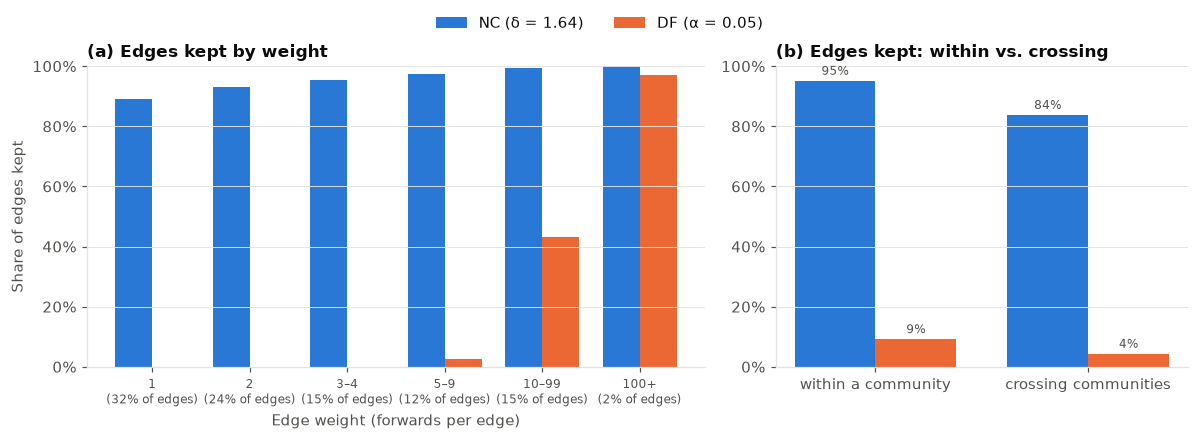

In [3]:
bins = [0, 1, 2, 4, 9, 99, np.inf]
labels = ["1", "2", "3–4", "5–9", "10–99", "100+"]
wclass = pd.cut(edges.weight, bins=bins, labels=labels)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [3, 2]})
x = np.arange(len(labels)); bw = 0.38
for i, (name, k) in enumerate(keep.items()):
    share = pd.Series(k).groupby(wclass.to_numpy(), observed=False).mean().reindex(labels)
    axes[0].bar(x + (i - 0.5) * bw, share, width=bw, color=plots.SERIES[i], label=name)
    vals = [k[~cross_main].mean(), k[cross_main].mean()]
    axes[1].bar(np.arange(2) + (i - 0.5) * bw, vals, width=bw, color=plots.SERIES[i], label=name)
    for xi, v in zip(np.arange(2) + (i - 0.5) * bw, vals):
        axes[1].text(xi, v + 0.02, f"{v:.0%}", ha="center", fontsize=8, color=plots.INK_2)
counts = wclass.value_counts().reindex(labels)
axes[0].set_xticks(x, [f"{l}\n({c / len(edges):.0%} of edges)" for l, c in zip(labels, counts)], fontsize=8)
axes[0].set_xlabel("Edge weight (forwards per edge)"); axes[0].set_ylabel("Share of edges kept")
axes[0].set_title("(a) Edges kept by weight", loc="left")
axes[1].set_xticks([0, 1], ["within a community", "crossing communities"])
axes[1].set_title("(b) Edges kept: within vs. crossing", loc="left")
for ax in axes:
    ax.set_ylim(0, 1); ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}"); ax.grid(axis="x", visible=False)
handles, lbls = axes[0].get_legend_handles_labels()
fig.legend(handles, lbls, loc="upper center", ncol=2, bbox_to_anchor=(0.5, 1.06))
fig.tight_layout()
plots.savefig(fig, "02b_fig1_retention", OUT)
plt.show()

## 2 · Leiden on each backbone

Same settings as the main run (D1): RB configuration, resolution 1.0, directed, weighted, seed 42, until
convergence. Channels left without any backbone edge get no community.

In [4]:
parts, metas = {}, {}
for tag, (name, k) in zip(["nc", "df"], keep.items()):
    gb = graph.to_igraph(edges[k])
    mem, meta = graph.leiden(gb)
    meta.update({"backbone": name, "edges_kept": int(k.sum())})
    part = pd.Series(mem.astype("int32"), index=pd.Index(np.asarray(gb.vs["channel_id"], dtype="int64"), name="channel_id"),
                     name="community")
    part.reset_index().to_parquet(cfg.DERIVED / f"communities_bb_{tag}.parquet", index=False)
    (cfg.DERIVED / f"communities_bb_{tag}_meta.json").write_text(json.dumps(meta, indent=2))
    parts[name], metas[name] = part, meta
    print(f"{name}: {meta['n_communities']} communities on {meta['nodes']:,} channels, "
          f"directed modularity {meta['modularity_directed']:.3f}, {meta['seconds']:.0f} s")

NC (δ = 1.64): 295 communities on 120,715 channels, directed modularity 0.866, 149 s
DF (α = 0.05): 1987 communities on 82,404 channels, directed modularity 0.889, 17 s


## 3 · Comparison with the main partition

Crossing rates and impurity are computed on the channels and forwards that have a community in **both**
partitions, and the main partition is evaluated on the same subset, so the columns are comparable (D14).

In [5]:
ch_all = channels.set_index("channel_id")
sab = set(channels.channel_id[channels.sabmyk])

def compare(part):
    common = part.index.intersection(main.index)
    a, b = main.reindex(common), part.reindex(common)
    _, cov = crossing_mask(edges_en, part)
    t = edges_en.n_text.to_numpy()
    xm, _ = crossing_mask(edges_en, main)
    xb, _ = crossing_mask(edges_en, part)
    chb = ch_all.loc[common].reset_index().assign(community=b.to_numpy())
    chm = ch_all.loc[common].reset_index().assign(community=a.to_numpy())
    sab_c = b[b.index.isin(sab)].value_counts()
    bl_b = blocks(edges_en, "n_text", part, cons_of).loc["across communities"]
    bl_m = blocks(edges_en[cov], "n_text", main, cons_of).loc["across communities"]
    sizes = part.value_counts()
    return {
        "channels with a community": len(part),
        "communities": part.nunique(),
        "communities with ≥ 100 channels": int((sizes >= 100).sum()),
        "NMI with main partition": ig.compare_communities(pd.factorize(a)[0].tolist(), pd.factorize(b)[0].tolist(), method="nmi"),
        "adjusted Rand with main partition": ig.compare_communities(pd.factorize(a)[0].tolist(), pd.factorize(b)[0].tolist(), method="adjusted_rand"),
        "Sabmyk channels in one community": f"{sab_c.iloc[0]} of {len(sab & set(part.index))}",
        "English text forwards covered": t[cov].sum() / t.sum(),
        "crossing share, English text forwards (this partition)": t[xb].sum() / t[cov].sum(),
        "crossing share, same forwards, main partition": t[xm & cov].sum() / t[cov].sum(),
        "conspiracy impurity reduction (this partition)": impurity_summary(chb, composition(chb))["impurity_reduction"],
        "conspiracy impurity reduction, same channels, main partition": impurity_summary(chm, composition(chm))["impurity_reduction"],
        "crossings involving a conspiracy channel (this partition)": 1 - bl_b["N→N"] / bl_b.sum(),
        "crossings involving a conspiracy channel, main partition": 1 - bl_m["N→N"] / bl_m.sum(),
    }

cmp = pd.DataFrame({"main (notebook 02)": compare(main), **{name: compare(p) for name, p in parts.items()}})
cmp.to_csv(OUT / "02b_comparison.csv")
def fmt(row):
    if row.name.startswith(("NMI", "adjusted")):
        return row.map(lambda v: f"{v:.3f}")
    return row.map(lambda v: v if isinstance(v, str) else f"{v:.1%}" if v <= 1 else f"{v:,.0f}")
cmp.apply(fmt, axis=1)

,main (notebook 02),NC (δ = 1.64),DF (α = 0.05)
channels with a community,"120,715","120,715","82,404"
communities,289,295,"1,987"
communities with ≥ 100 channels,34,33,44
NMI with main partition,1.000,0.976,0.816
adjusted Rand with main partition,1.000,0.977,0.769
Sabmyk channels in one community,234 of 236,234 of 236,233 of 236
English text forwards covered,100.0%,100.0%,99.2%
"crossing share, English text forwards (this partition)",5.0%,5.1%,5.5%
"crossing share, same forwards, main partition",5.0%,5.0%,5.0%
conspiracy impurity reduction (this partition),34.7%,34.3%,42.2%


**How the 15 largest main communities map onto the backbone communities.** `overlap` = share of the main
community's channels (those that kept a community) that fall in its most common backbone community;
`kept` = share of its channels that still have a community at all. Low overlap = the backbone splits it.

In [6]:
rows = []
for c in range(15):
    members = main.index[main == c]
    row = {"main_community": c, "channels": len(members), "languages": mix(ch_all.language.reindex(members)),
           "conspiracy_share": ch_all.conspiracy.reindex(members).mean()}
    for name, part in parts.items():
        tag = name.split(" ")[0]
        p = part.reindex(members).dropna()
        vc = p.value_counts()
        row[f"{tag} kept"] = len(p) / len(members)
        row[f"{tag} main target"] = f"B{int(vc.index[0])}"
        row[f"{tag} overlap"] = vc.iloc[0] / len(p)
        row[f"{tag} pieces ≥ 5%"] = int((vc / len(p) >= 0.05).sum())
    rows.append(row)
mapping = pd.DataFrame(rows).set_index("main_community")
mapping.style.format({c: "{:.0%}" for c in mapping.columns if "kept" in c or "overlap" in c or c == "conspiracy_share"} | {"channels": "{:,}"})

,channels,languages,conspiracy_share,NC kept,NC main target,NC overlap,NC pieces ≥ 5%,DF kept,DF main target,DF overlap,DF pieces ≥ 5%
main_community,,,,,,,,,,,
0,"21,885","ru 94%, unknown 4%, en 1%",5%,100%,B0,99%,1,70%,B0,85%,1
1,"20,504","ru 68%, unknown 24%, en 4%",3%,100%,B1,99%,1,61%,B1,87%,1
2,"16,822","fa 94%, unknown 4%, en 1%",1%,100%,B2,100%,1,64%,B2,64%,2
3,"9,258","unknown 69%, ru 14%, bg 10%",0%,100%,B3,99%,1,67%,B3,79%,2
4,"6,386","en 35%, unknown 34%, it 22%",4%,100%,B4,100%,1,62%,B5,84%,1
5,"5,674","de 86%, unknown 9%, en 4%",51%,100%,B5,100%,1,83%,B4,98%,1
6,"5,067","en 78%, unknown 13%, es 2%",35%,100%,B6,99%,1,71%,B7,89%,1
7,"4,099","en 93%, unknown 4%, nl 1%",67%,100%,B7,98%,1,84%,B6,93%,1
8,"3,878","en 81%, unknown 15%, ar 2%",1%,100%,B9,100%,1,73%,B9,95%,1


## 4 · Summary for the discussion

In [7]:
r, c = retention, cmp
nc, df = list(keep)
print(f'''Backbone prototype (DECISIONS D14), full graph of {len(edges):,} edges / {w.sum():,} forwards.
                                   {nc:>15} {df:>15}
  edges kept                       {r.loc['edges kept', nc]:>15.1%} {r.loc['edges kept', df]:>15.1%}
  forwards kept                    {r.loc['forwards kept', nc]:>15.1%} {r.loc['forwards kept', df]:>15.1%}
  channels kept                    {r.iloc[0][nc]:>15.1%} {r.iloc[0][df]:>15.1%}
  crossing edges kept              {r.loc['crossing edges kept (main partition)', nc]:>15.1%} {r.loc['crossing edges kept (main partition)', df]:>15.1%}
  within-community edges kept      {r.loc['within-community edges kept (main partition)', nc]:>15.1%} {r.loc['within-community edges kept (main partition)', df]:>15.1%}
  communities                      {c.loc['communities', nc]:>15,} {c.loc['communities', df]:>15,}   (main: {c.loc['communities', 'main (notebook 02)']})
  NMI / ARI with main              {c.loc['NMI with main partition', nc]:>7.3f} / {c.loc['adjusted Rand with main partition', nc]:.3f} {c.loc['NMI with main partition', df]:>7.3f} / {c.loc['adjusted Rand with main partition', df]:.3f}
  English text crossing share      {c.loc['crossing share, English text forwards (this partition)', nc]:>15.1%} {c.loc['crossing share, English text forwards (this partition)', df]:>15.1%}
    main partition, same forwards  {c.loc['crossing share, same forwards, main partition', nc]:>15.1%} {c.loc['crossing share, same forwards, main partition', df]:>15.1%}
  Sabmyk in one community          {c.loc['Sabmyk channels in one community', nc]:>15} {c.loc['Sabmyk channels in one community', df]:>15}''')

Backbone prototype (DECISIONS D14), full graph of 4,676,642 edges / 57,947,677 forwards.
                                     NC (δ = 1.64)   DF (α = 0.05)
  edges kept                                 93.7%            8.6%
  forwards kept                              99.0%           69.8%
  channels kept                             100.0%           68.3%
  crossing edges kept                        83.8%            4.3%
  within-community edges kept                95.1%            9.2%
  communities                                  295           1,987   (main: 289)
  NMI / ARI with main                0.976 / 0.977   0.816 / 0.769
  English text crossing share                 5.1%            5.5%
    main partition, same forwards             5.0%            5.0%
  Sabmyk in one community               234 of 236      233 of 236
